1. Data ingestion and validation

In [91]:
import os
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")

if not os.path.exists("European_Bank.csv"):
    from google.colab import files
    files.upload()          # choose European_Bank.csv

df = pd.read_csv("European_Bank.csv")
print("Shape:", df.shape, "| Nulls:", df.isna().sum().sum(), "| Dup rows:", df.duplicated().sum())
print("NumOfProducts:", df["NumOfProducts"].value_counts().sort_index().to_dict())
print("Tenure range:", df["Tenure"].min(), "-", df["Tenure"].max(), "| Zero-balance share:", round((df["Balance"]==0).mean(),3))
for c in ["HasCrCard","IsActiveMember","Exited"]:
    assert set(df[c].unique()) <= {0,1}, c
print("Binary columns OK (0/1 only)")
print("Churn rate:", round(df["Exited"].mean(),4))
print(df.groupby("NumOfProducts")["Exited"].agg(["mean","count"]).round(3))

Shape: (10000, 14) | Nulls: 0 | Dup rows: 0
NumOfProducts: {1: 5084, 2: 4590, 3: 266, 4: 60}
Tenure range: 0 - 10 | Zero-balance share: 0.362
Binary columns OK (0/1 only)
Churn rate: 0.2037
                mean  count
NumOfProducts              
1              0.277   5084
2              0.076   4590
3              0.827    266
4              1.000     60


2. Data cleaning and preparation

In [92]:
df = df.drop(columns=["Surname", "Year"])        # non-analytical (Year is constant)
for c in ["Geography", "Gender"]:
    df[c] = df[c].astype("category")
pos_median = df.loc[df["Balance"] > 0, "Balance"].median()

df["AgeGroup"]    = pd.cut(df["Age"], [0, 29, 45, 60, 120], labels=["<30", "30-45", "46-60", "60+"])
df["CreditBand"]  = pd.cut(df["CreditScore"], [0, 599, 699, 900], labels=["Low", "Medium", "High"])
df["TenureGroup"] = pd.cut(df["Tenure"], [-1, 2, 6, 10], labels=["New (0-2)", "Mid-term (3-6)", "Long-term (7-10)"])
df["BalanceSeg"]  = np.where(df["Balance"] == 0, "Zero-balance",
                      np.where(df["Balance"] <= pos_median, "Low-balance", "High-balance"))
df["BalanceSeg"]  = pd.Categorical(df["BalanceSeg"], ["Zero-balance", "Low-balance", "High-balance"], ordered=True)

print("Median of positive balances (Low/High cutoff):", round(pos_median, 2))
for c in ["AgeGroup","CreditBand","TenureGroup","BalanceSeg"]:
    print(c, df[c].value_counts().sort_index().to_dict())

Median of positive balances (Low/High cutoff): 119839.69
AgeGroup {'<30': 1641, '30-45': 6248, '46-60': 1647, '60+': 464}
CreditBand {'Low': 3034, 'Medium': 3818, 'High': 3148}
TenureGroup {'New (0-2)': 2496, 'Mid-term (3-6)': 3977, 'Long-term (7-10)': 3527}
BalanceSeg {'Zero-balance': 3617, 'Low-balance': 3192, 'High-balance': 3191}


3. Churn distribution analysis

Overall churn rate: 20.37 % ( 2037 of 10000 )

--- Geography ---
           Customers  Churned  ChurnRate  SizeShare%  ChurnContribution%  Lift
Geography                                                                     
France          5014      810      16.15       50.14               39.76  0.79
Germany         2509      814      32.44       25.09               39.96  1.59
Spain           2477      413      16.67       24.77               20.27  0.82

--- AgeGroup ---
          Customers  Churned  ChurnRate  SizeShare%  ChurnContribution%  Lift
AgeGroup                                                                     
<30            1641      124       7.56       16.41                6.09  0.37
30-45          6248      956      15.30       62.48               46.93  0.75
46-60          1647      842      51.12       16.47               41.34  2.51
60+             464      115      24.78        4.64                5.65  1.22

--- CreditBand ---
            Customers  Churned  Ch

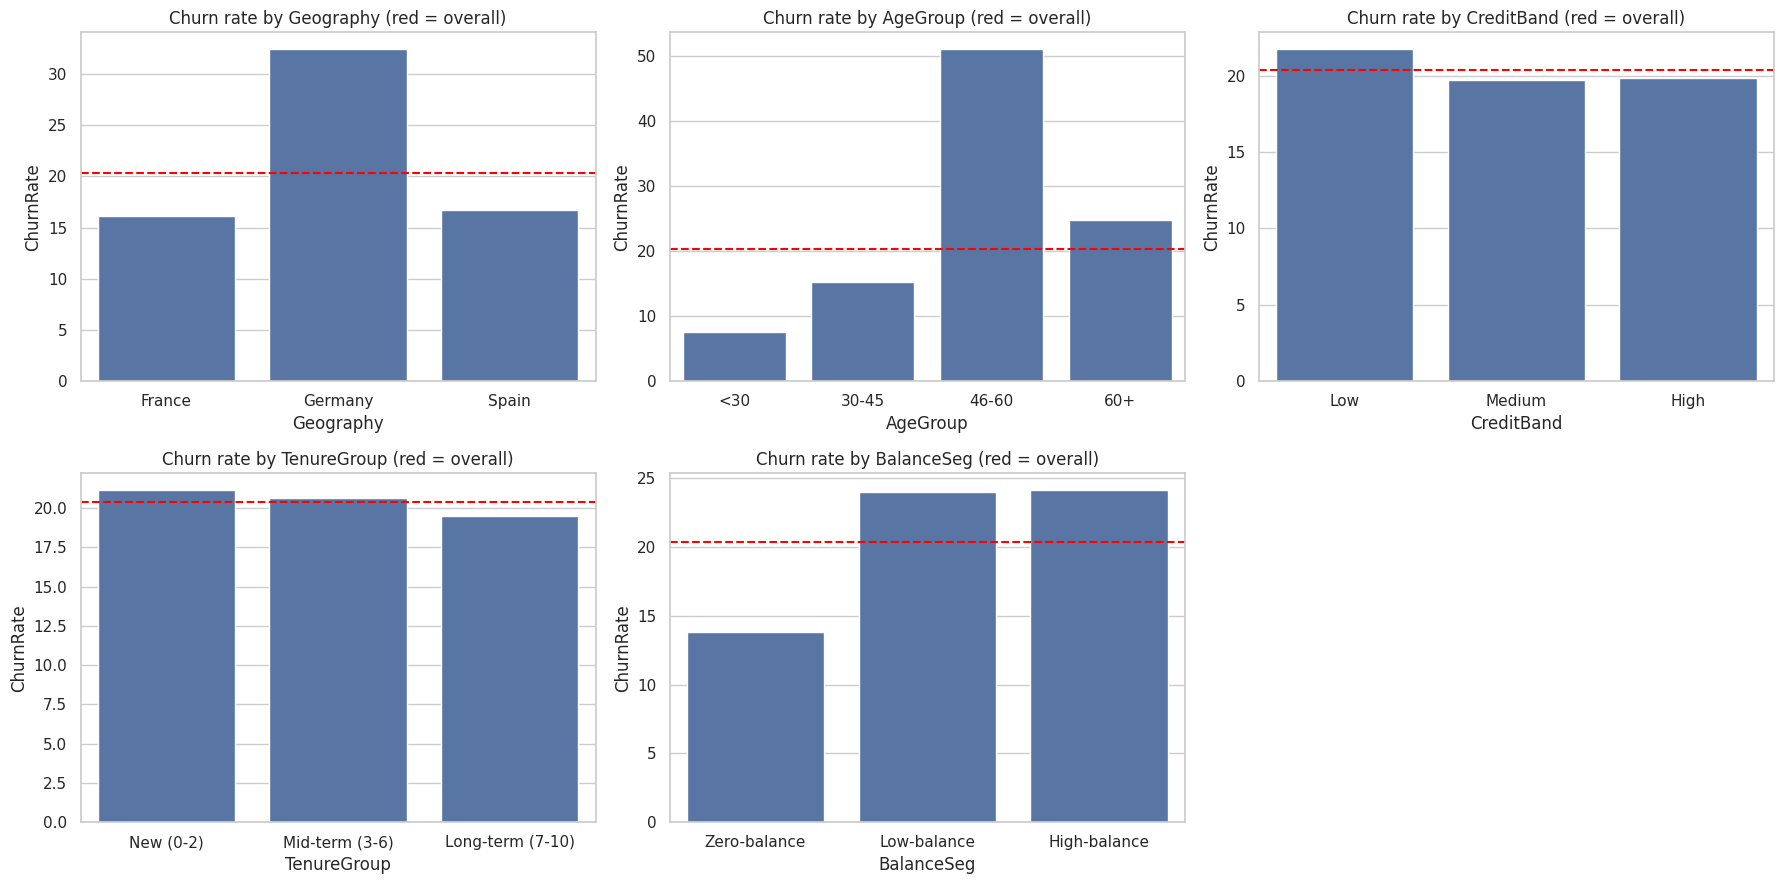


--- Churned vs Retained profile (means) ---
                 Retained    Churned  Diff%
CreditScore        651.85     645.35  -1.00
Age                 37.41      44.84  19.86
Tenure               5.03       4.93  -2.00
Balance          72745.30   91108.54  25.24
NumOfProducts        1.54       1.48  -4.47
HasCrCard            0.71       0.70  -1.14
IsActiveMember       0.55       0.36 -34.94
EstimatedSalary  99738.39  101465.68   1.73


In [93]:
total_churn = df["Exited"].sum()
print("Overall churn rate:", round(df["Exited"].mean()*100, 2), "% (", total_churn, "of", len(df), ")")

def seg_table(col):
    g = df.groupby(col, observed=True).agg(Customers=("Exited","size"), Churned=("Exited","sum"), ChurnRate=("Exited","mean"))
    g["SizeShare%"]         = g["Customers"]/len(df)*100
    g["ChurnContribution%"] = g["Churned"]/total_churn*100
    g["Lift"]               = g["ChurnRate"]/df["Exited"].mean()
    g["ChurnRate"]          = g["ChurnRate"]*100
    return g.round(2)

seg_cols = ["Geography","AgeGroup","CreditBand","TenureGroup","BalanceSeg"]
tables = {c: seg_table(c) for c in seg_cols}
for c, t in tables.items():
    print(f"\n--- {c} ---")
    print(t.to_string())

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, c in zip(axes.ravel(), seg_cols):
    t = tables[c]
    sns.barplot(x=t.index.astype(str), y=t["ChurnRate"], ax=ax)
    ax.axhline(df["Exited"].mean()*100, color="red", ls="--")
    ax.set_title(f"Churn rate by {c} (red = overall)")
axes[1,2].axis("off")
plt.tight_layout()
plt.show()

# Churned vs retained profile
prof = df.groupby("Exited")[["CreditScore","Age","Tenure","Balance","NumOfProducts","HasCrCard","IsActiveMember","EstimatedSalary"]].mean().T
prof.columns = ["Retained", "Churned"]
prof["Diff%"] = (prof["Churned"]/prof["Retained"]-1)*100
print("\n--- Churned vs Retained profile (means) ---")
print(prof.round(2).to_string())

4. Comparative demographic analysis

--- Gender churn % ---
         mean  count
Gender              
Female  25.07   4543
Male    16.46   5457

--- Geography x Gender churn % ---
Gender     Female  Male
Geography              
France       20.3  12.7
Germany      37.6  27.8
Spain        21.2  13.1

--- Geography x AgeGroup churn % ---
AgeGroup    <30  30-45  46-60   60+
Geography                          
France      5.2   11.9   45.8  19.9
Germany    12.6   25.3   67.3  38.9
Spain       7.9   12.5   40.7  20.8

--- Geography x AgeGroup customer counts ---
AgeGroup   <30  30-45  46-60  60+
Geography                        
France     866   3168    749  231
Germany    372   1522    502  113
Spain      403   1558    396  120


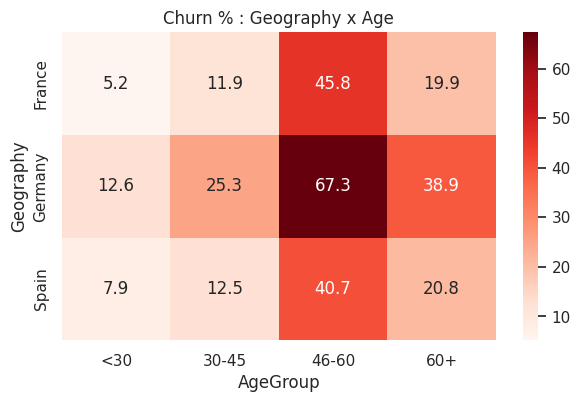


--- Credit band x Balance segment churn % ---
BalanceSeg  Zero-balance  Low-balance  High-balance
CreditBand                                         
Low                 14.5         27.0          25.1
Medium              13.7         22.0          24.1
High                13.3         23.6          23.4

--- Salary quartile churn % ---
SalaryBand
Q1 low     20.00
Q2         19.80
Q3         20.12
Q4 high    21.56
Name: Exited, dtype: float64

--- Active x Credit band churn % ---
CreditBand       Low  Medium  High
IsActiveMember                    
0               27.7    26.2  26.7
1               15.6    13.8  13.6


In [94]:
print("--- Gender churn % ---")
print((df.groupby("Gender", observed=True)["Exited"].agg(["mean","count"])*[100,1]).round(2))
print("\n--- Geography x Gender churn % ---")
print((pd.crosstab(df["Geography"], df["Gender"], values=df["Exited"], aggfunc="mean")*100).round(1))
print("\n--- Geography x AgeGroup churn % ---")
ga = pd.crosstab(df["Geography"], df["AgeGroup"], values=df["Exited"], aggfunc="mean")*100
print(ga.round(1))
print("\n--- Geography x AgeGroup customer counts ---")
print(pd.crosstab(df["Geography"], df["AgeGroup"]))

plt.figure(figsize=(7,4))
sns.heatmap(ga, annot=True, fmt=".1f", cmap="Reds")
plt.title("Churn % : Geography x Age")
plt.show()

# Financial stability vs churn
df["SalaryBand"] = pd.qcut(df["EstimatedSalary"], 4, labels=["Q1 low","Q2","Q3","Q4 high"])
print("\n--- Credit band x Balance segment churn % ---")
print((pd.crosstab(df["CreditBand"], df["BalanceSeg"], values=df["Exited"], aggfunc="mean")*100).round(1))
print("\n--- Salary quartile churn % ---")
print((df.groupby("SalaryBand", observed=True)["Exited"].mean()*100).round(2))
print("\n--- Active x Credit band churn % ---")
print((pd.crosstab(df["IsActiveMember"], df["CreditBand"], values=df["Exited"], aggfunc="mean")*100).round(1))

5. High-value customer churn analysis

High-value threshold (top 25% balance): 127,644 | top 10%: 149,245
High-value customers: 2500 | churned: 592 | churn rate: 23.68 %

High-balance churners by geography: {'Germany': 274, 'France': 214, 'Spain': 104}
Hgh-balance churners by age group: {'<30': 43, '30-45': 292, '46-60': 224, '60+': 33}
High-balance churners by products: {1: 416, 2: 93, 3: 63, 4: 20}
High-balance churners inactive share: 64.2 %

--- Salary quartile x Balance quartile churn % ---
BalanceQ    Q1 low    Q2    Q3  Q4 high
SalaryBand                             
Q1 low        13.4  15.0  28.0     23.8
Q2            14.7  16.9  25.6     22.1
Q3            14.8  17.1  24.7     23.8
Q4 high       15.7  18.5  26.9     25.0


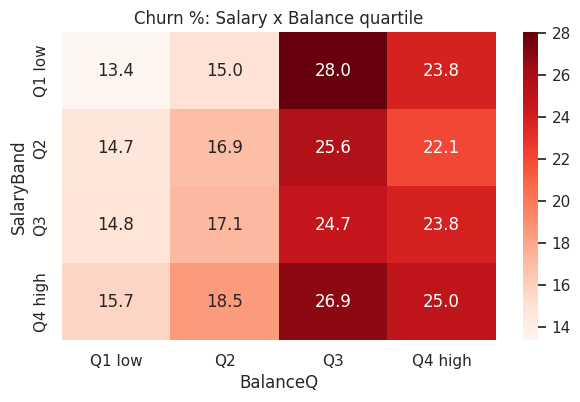


Median Balance/Salary ratio (balance>0): churned = 1.18 | retained = 1.2

--- Revenue risk (balance as proxy) ---
Total balances: 764,858,893
Balances held by churned customers: 185,588,095  (24.3% of total)
Avg balance churned: 91,109 vs retained: 72,745
High-value churners' balances: 88,654,932 = 47.8% of all lost balance

Balance lost by geography (%): {'France': 31.1, 'Germany': 52.8, 'Spain': 16.1}
Balance lost by balance segment (%): {'Zero-balance': 0.0, 'Low-balance': 40.3, 'High-balance': 59.7}

Annual revenue at risk @ 2% margin: 3,711,762 | high-value churners only: 1,773,099


In [95]:
q75 = df["Balance"].quantile(0.75)
q90 = df["Balance"].quantile(0.90)
df["HighValue"] = df["Balance"] >= q75
print(f"High-value threshold (top 25% balance): {q75:,.0f} | top 10%: {q90:,.0f}")
hv = df[df["HighValue"]]
print("High-value customers:", len(hv), "| churned:", hv["Exited"].sum(), "| churn rate:", round(hv["Exited"].mean()*100,2), "%")
print("\nHigh-balance churners by geography:", hv[hv.Exited==1]["Geography"].value_counts().to_dict())
print("Hgh-balance churners by age group:", hv[hv.Exited==1]["AgeGroup"].value_counts().sort_index().to_dict())
print("High-balance churners by products:", hv[hv.Exited==1]["NumOfProducts"].value_counts().sort_index().to_dict())
print("High-balance churners inactive share:", round((hv[hv.Exited==1]["IsActiveMember"]==0).mean()*100,1), "%")

# Salary vs balance patterns
df["BalSalRatio"] = df["Balance"]/df["EstimatedSalary"]
df["BalanceQ"] = pd.qcut(df["Balance"].rank(method="first"), 4, labels=["Q1 low","Q2","Q3","Q4 high"])
print("\n--- Salary quartile x Balance quartile churn % ---")
sb = pd.crosstab(df["SalaryBand"], df["BalanceQ"], values=df["Exited"], aggfunc="mean")*100
print(sb.round(1))

plt.figure(figsize=(7,4))
sns.heatmap(sb, annot=True, fmt=".1f", cmap="Reds")
plt.title("Churn %: Salary x Balance quartile")
plt.show()

print("\nMedian Balance/Salary ratio (balance>0): churned =",
      round(df[(df.Exited==1)&(df.Balance>0)]["BalSalRatio"].median(),2), "| retained =",
      round(df[(df.Exited==0)&(df.Balance>0)]["BalSalRatio"].median(),2))

# Revenue risk (balance used as a proxy, there is no revenue column)
tot_bal  = df["Balance"].sum()
lost_bal = df.loc[df.Exited==1, "Balance"].sum()
hv_lost  = hv.loc[hv.Exited==1, "Balance"].sum()
print("\n--- Revenue risk (balance as proxy) ---")
print(f"Total balances: {tot_bal:,.0f}")
print(f"Balances held by churned customers: {lost_bal:,.0f}  ({lost_bal/tot_bal*100:.1f}% of total)")
print(f"Avg balance churned: {df[df.Exited==1]['Balance'].mean():,.0f} vs retained: {df[df.Exited==0]['Balance'].mean():,.0f}")
print(f"High-value churners' balances: {hv_lost:,.0f} = {hv_lost/lost_bal*100:.1f}% of all lost balance")
print("\nBalance lost by geography (%):", (df[df.Exited==1].groupby("Geography", observed=True)["Balance"].sum()/lost_bal*100).round(1).to_dict())
print("Balance lost by balance segment (%):", (df[df.Exited==1].groupby("BalanceSeg", observed=True)["Balance"].sum()/lost_bal*100).round(1).to_dict())

NIM = 0.02   # ASSUMPTION: 2% annual net interest margin on balances; replace with your bank's figure
print(f"\nAnnual revenue at risk @ {NIM:.0%} margin: {lost_bal*NIM:,.0f} | high-value churners only: {hv_lost*NIM:,.0f}")

6. Key Performance Indicators (KPIs)


In [96]:
# ---------- KPI 1: Overall Churn Rate ----------
overall = df["Exited"].mean()
print(f"KPI 1 - Overall Churn Rate: {overall:.2%}  ({df['Exited'].sum()} of {len(df)})")

# ---------- KPI 2: Segment Churn Rate ----------
rows = []
for col in ["Geography", "Gender", "AgeGroup", "CreditBand", "TenureGroup", "BalanceSeg"]:
    g = df.groupby(col, observed=True)["Exited"].agg(["size", "sum", "mean"])
    for seg, r in g.iterrows():
        rows.append([col, str(seg), int(r["size"]), int(r["sum"]),
                     round(r["mean"]*100, 2), round(r["mean"]/overall, 2)])
seg_kpi = pd.DataFrame(rows, columns=["Dimension", "Segment", "Customers", "Churned", "ChurnRate%", "VsOverall(x)"])
print("\nKPI 2 - Segment Churn Rate"); print(seg_kpi.to_string(index=False))

# ---------- KPI 3: High-Value Churn Ratio ----------
q75 = df["Balance"].quantile(0.75)                 # premium = top 25% by balance
hv = df[df["Balance"] >= q75]
hv_rate = hv["Exited"].mean()
print(f"\nKPI 3 - High-Value Churn Ratio (top 25% balance, >= {q75:,.0f})")
print(f"  High-value churn rate: {hv_rate:.2%} ({hv['Exited'].sum()} of {len(hv)})")
print(f"  Ratio vs overall churn: {hv_rate/overall:.2f}x")
print(f"  Share of all churned balance held by high-value churners: "
      f"{hv.loc[hv.Exited==1,'Balance'].sum()/df.loc[df.Exited==1,'Balance'].sum():.1%}")

# ---------- KPI 4: Geographic Risk Index ----------
geo = df.groupby("Geography", observed=True)["Exited"].mean()
gri = (geo/overall*100).round(1)                   # 100 = bank average
lost = df[df.Exited==1].groupby("Geography", observed=True)["Balance"].sum()
geo_kpi = pd.DataFrame({"ChurnRate%": (geo*100).round(2), "RiskIndex": gri,
                        "BalanceLost%": (lost/lost.sum()*100).round(1)})
geo_kpi["RiskLevel"] = np.where(geo_kpi["RiskIndex"] >= 120, "High",
                         np.where(geo_kpi["RiskIndex"] >= 90, "Medium", "Low"))
print("\nKPI 4 - Geographic Risk Index (100 = bank average)"); print(geo_kpi)

# ---------- KPI 5: Engagement Drop Indicator ----------
act = df.groupby("IsActiveMember")["Exited"].mean()
print("\nKPI 5 - Engagement Drop Indicator")
print(f"  Inactive churn: {act[0]:.2%} | Active churn: {act[1]:.2%}")
print(f"  Gap: {(act[0]-act[1])*100:.2f} pts | Ratio: {act[0]/act[1]:.2f}x")
print(f"  Inactive share of all customers: {(df.IsActiveMember==0).mean():.1%} | "
      f"of all churners: {(df[df.Exited==1].IsActiveMember==0).mean():.1%}")

KPI 1 - Overall Churn Rate: 20.37%  (2037 of 10000)

KPI 2 - Segment Churn Rate
  Dimension          Segment  Customers  Churned  ChurnRate%  VsOverall(x)
  Geography           France       5014      810       16.15          0.79
  Geography          Germany       2509      814       32.44          1.59
  Geography            Spain       2477      413       16.67          0.82
     Gender           Female       4543     1139       25.07          1.23
     Gender             Male       5457      898       16.46          0.81
   AgeGroup              <30       1641      124        7.56          0.37
   AgeGroup            30-45       6248      956       15.30          0.75
   AgeGroup            46-60       1647      842       51.12          2.51
   AgeGroup              60+        464      115       24.78          1.22
 CreditBand              Low       3034      660       21.75          1.07
 CreditBand           Medium       3818      753       19.72          0.97
 CreditBand         

In [97]:
%%writefile app.py
import os
import numpy as np
import pandas as pd
import plotly.express as px
import streamlit as st

st.set_page_config(page_title="European Bank Churn Dashboard", page_icon="🏦", layout="wide")

# ------------------------------------------------------------------ DATA
@st.cache_data
def prepare(raw: pd.DataFrame) -> pd.DataFrame:
    df = raw.drop(columns=[c for c in ["Surname", "Year"] if c in raw.columns]).copy()
    pos_median = df.loc[df["Balance"] > 0, "Balance"].median()
    df["AgeGroup"] = pd.cut(df["Age"], [0, 29, 45, 60, 120], labels=["<30", "30-45", "46-60", "60+"])
    df["CreditBand"] = pd.cut(df["CreditScore"], [0, 599, 699, 900], labels=["Low", "Medium", "High"])
    df["TenureGroup"] = pd.cut(df["Tenure"], [-1, 2, 6, 10],
                               labels=["New (0-2)", "Mid-term (3-6)", "Long-term (7-10)"])
    df["BalanceSeg"] = np.where(df["Balance"] == 0, "Zero-balance",
                         np.where(df["Balance"] <= pos_median, "Low-balance", "High-balance"))
    df["BalanceSeg"] = pd.Categorical(df["BalanceSeg"],
                         ["Zero-balance", "Low-balance", "High-balance"], ordered=True)
    df["Status"] = np.where(df["Exited"] == 1, "Churned", "Retained")
    df["Engagement"] = np.where(df["IsActiveMember"] == 1, "Active", "Inactive")
    return df

st.title("🏦 European Bank: Customer Churn Dashboard")

if os.path.exists("European_Bank.csv"):
    raw = pd.read_csv("European_Bank.csv")
else:
    up = st.file_uploader("Upload European_Bank.csv", type="csv")
    if up is None:
        st.info("Upload the dataset to start.")
        st.stop()
    raw = pd.read_csv(up)

full = prepare(raw)
overall_rate = full["Exited"].mean()

# --------------------------------------------------------------- FILTERS
st.sidebar.header("Segment filters")
geo = st.sidebar.multiselect("Geography", sorted(full["Geography"].unique()), default=sorted(full["Geography"].unique()))
gender = st.sidebar.multiselect("Gender", sorted(full["Gender"].unique()), default=sorted(full["Gender"].unique()))
age_rng = st.sidebar.slider("Age", int(full.Age.min()), int(full.Age.max()), (int(full.Age.min()), int(full.Age.max())))
ten_rng = st.sidebar.slider("Tenure (years)", 0, 10, (0, 10))
credit = st.sidebar.multiselect("Credit band", ["Low", "Medium", "High"], default=["Low", "Medium", "High"])
bal_seg = st.sidebar.multiselect("Balance segment", ["Zero-balance", "Low-balance", "High-balance"],
                                 default=["Zero-balance", "Low-balance", "High-balance"])
engage = st.sidebar.multiselect("Engagement", ["Active", "Inactive"], default=["Active", "Inactive"])
prods = st.sidebar.multiselect("Number of products", sorted(full["NumOfProducts"].unique()),
                               default=sorted(full["NumOfProducts"].unique()))

df = full[
    full["Geography"].isin(geo) & full["Gender"].isin(gender)
    & full["Age"].between(*age_rng) & full["Tenure"].between(*ten_rng)
    & full["CreditBand"].isin(credit) & full["BalanceSeg"].isin(bal_seg)
    & full["Engagement"].isin(engage) & full["NumOfProducts"].isin(prods)
]
st.sidebar.caption(f"{len(df):,} of {len(full):,} customers selected")

if df.empty:
    st.warning("No customers match the current filters. Widen the filters in the sidebar.")
    st.stop()

# ------------------------------------------------------------ DYNAMIC KPIs
rate = df["Exited"].mean()
hv_cut = full["Balance"].quantile(0.75)            # premium = top 25% balance of the full base
hv = df[df["Balance"] >= hv_cut]
act = df.groupby("Engagement")["Exited"].mean()

c1, c2, c3, c4, c5 = st.columns(5)
c1.metric("Customers", f"{len(df):,}")
c2.metric("Churned", f"{int(df.Exited.sum()):,}")
c3.metric("Churn rate", f"{rate:.2%}", f"{(rate-overall_rate)*100:+.2f} pts vs overall", delta_color="inverse")
c4.metric("High-value churn", f"{hv['Exited'].mean():.2%}" if len(hv) else "n/a",
          f"{len(hv):,} premium customers")
if {"Active", "Inactive"} <= set(act.index):
    c5.metric("Inactive vs active churn", f"{act['Inactive']:.1%} vs {act['Active']:.1%}",
              f"{act['Inactive']/act['Active']:.2f}x", delta_color="inverse")
else:
    c5.metric("Engagement gap", "n/a", "select both groups")

tab1, tab2, tab3, tab4, tab5 = st.tabs(
    ["Overall summary", "Geography", "Age & Tenure", "High-value explorer", "Drill-down"])

def rate_bar(data, col, title):
    t = data.groupby(col, observed=True)["Exited"].agg(Customers="size", Churned="sum", ChurnRate="mean").reset_index()
    t["ChurnRate%"] = (t["ChurnRate"] * 100).round(2)
    fig = px.bar(t, x=col, y="ChurnRate%", text="ChurnRate%", hover_data=["Customers", "Churned"], title=title)
    fig.add_hline(y=overall_rate * 100, line_dash="dash", line_color="red", annotation_text="overall")
    return fig, t

# ------------------------------------------------------- 1. OVERALL SUMMARY
with tab1:
    a, b = st.columns(2)
    donut = px.pie(df, names="Status", hole=0.55, title="Churned vs retained",
                   color="Status", color_discrete_map={"Churned": "#d62728", "Retained": "#1f77b4"})
    a.plotly_chart(donut, width="stretch")
    prof = df.groupby("Status")[["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts",
                                 "IsActiveMember", "EstimatedSalary"]].mean().T.round(2)
    b.subheader("Churned vs retained profile (means)")
    b.dataframe(prof, width="stretch")
    prod_fig, _ = rate_bar(df, "NumOfProducts", "Churn rate by number of products")
    st.plotly_chart(prod_fig, width="stretch")

# ------------------------------------------------------------- 2. GEOGRAPHY
with tab2:
    fig, t = rate_bar(df, "Geography", "Churn rate by geography")
    t["RiskIndex"] = (t["ChurnRate"] / overall_rate * 100).round(1)
    a, b = st.columns(2)
    a.plotly_chart(fig, width="stretch")
    b.subheader("Geographic Risk Index (100 = bank average)")
    b.dataframe(t[["Geography", "Customers", "Churned", "ChurnRate%", "RiskIndex"]], hide_index=True, width="stretch")
    heat = df.pivot_table(index="Geography", columns="AgeGroup", values="Exited", aggfunc="mean", observed=True) * 100
    st.plotly_chart(px.imshow(heat.round(1), text_auto=True, color_continuous_scale="Reds",
                              title="Churn % : Geography x Age group"), width="stretch")
    gender_fig = px.bar(df.groupby(["Geography", "Gender"], observed=True)["Exited"].mean().mul(100).round(1).reset_index(),
                        x="Geography", y="Exited", color="Gender", barmode="group", title="Churn % by geography and gender")
    st.plotly_chart(gender_fig, width="stretch")

# ---------------------------------------------------------- 3. AGE & TENURE
with tab3:
    a, b = st.columns(2)
    f1, _ = rate_bar(df, "AgeGroup", "Churn rate by age group")
    f2, _ = rate_bar(df, "TenureGroup", "Churn rate by tenure group")
    a.plotly_chart(f1, width="stretch")
    b.plotly_chart(f2, width="stretch")
    by_age = df.groupby("Age")["Exited"].mean().mul(100).reset_index()
    st.plotly_chart(px.line(by_age, x="Age", y="Exited", title="Churn % by exact age", labels={"Exited": "Churn %"}),
                    width="stretch")
    heat2 = df.pivot_table(index="TenureGroup", columns="AgeGroup", values="Exited", aggfunc="mean", observed=True) * 100
    st.plotly_chart(px.imshow(heat2.round(1), text_auto=True, color_continuous_scale="Reds",
                              title="Churn % : Tenure group x Age group"), width="stretch")

# ------------------------------------------------- 4. HIGH-VALUE EXPLORER
with tab4:
    pct = st.slider("Premium definition: top X% of customers by balance", 5, 50, 25, step=5)
    cut = full["Balance"].quantile(1 - pct / 100)
    hv2 = df[df["Balance"] >= cut]
    st.caption(f"Premium = balance >= {cut:,.0f}")
    if hv2.empty:
        st.warning("No premium customers in the current selection.")
    else:
        lost_all = df.loc[df.Exited == 1, "Balance"].sum()
        lost_hv = hv2.loc[hv2.Exited == 1, "Balance"].sum()
        k1, k2, k3, k4 = st.columns(4)
        k1.metric("Premium customers", f"{len(hv2):,}")
        k2.metric("Premium churn rate", f"{hv2.Exited.mean():.2%}")
        k3.metric("Ratio vs overall", f"{hv2.Exited.mean()/overall_rate:.2f}x")
        k4.metric("Balance lost (premium churners)", f"{lost_hv:,.0f}",
                  f"{lost_hv/lost_all:.1%} of all lost balance" if lost_all else None)
        st.plotly_chart(px.scatter(hv2, x="EstimatedSalary", y="Balance", color="Status", opacity=0.6,
                                   color_discrete_map={"Churned": "#d62728", "Retained": "#1f77b4"},
                                   title="Premium customers: salary vs balance"), width="stretch")
        dim = st.selectbox("Break premium churn down by", ["Geography", "AgeGroup", "Gender", "NumOfProducts", "Engagement"])
        f3, _ = rate_bar(hv2, dim, f"Premium churn rate by {dim}")
        st.plotly_chart(f3, width="stretch")
        churners = hv2[hv2.Exited == 1].sort_values("Balance", ascending=False)
        st.subheader(f"Premium churners ({len(churners):,})")
        cols = ["CustomerId", "Geography", "Gender", "Age", "Tenure", "Balance", "EstimatedSalary", "NumOfProducts", "Engagement"]
        st.dataframe(churners[cols], hide_index=True, width="stretch")
        st.download_button("Download premium churners (CSV)", churners[cols].to_csv(index=False), "premium_churners.csv", "text/csv")

# ------------------------------------------------------------ 5. DRILL-DOWN
with tab5:
    st.write("Pick a level-1 dimension and value, then break that segment down further.")
    dims = ["Geography", "Gender", "AgeGroup", "CreditBand", "TenureGroup", "BalanceSeg", "Engagement", "NumOfProducts"]
    d1 = st.selectbox("Level 1 dimension", dims, index=0)
    fig1, _ = rate_bar(df, d1, f"Churn rate by {d1}")
    st.plotly_chart(fig1, width="stretch")
    v1 = st.selectbox(f"Drill into {d1} =", sorted(df[d1].dropna().unique().tolist(), key=str))
    seg = df[df[d1] == v1]
    st.write(f"**{d1} = {v1}**: {len(seg):,} customers, churn rate {seg.Exited.mean():.2%}")
    d2 = st.selectbox("Level 2 dimension", [d for d in dims if d != d1], index=1)
    fig2, t2 = rate_bar(seg, d2, f"Within {d1} = {v1}: churn rate by {d2}")
    st.plotly_chart(fig2, width="stretch")
    st.dataframe(t2.drop(columns="ChurnRate"), hide_index=True, width="stretch")
    with st.expander("Show customer records in this segment"):
        st.dataframe(seg.drop(columns=["Status"]).head(500), hide_index=True, width="stretch")

Overwriting app.py


In [98]:
import py_compile
py_compile.compile("app.py", doraise=True)
print("app.py is valid Python")
!ls -l /content/European_Bank.csv

app.py is valid Python
-rw-r--r-- 1 root root 685959 Nov  5 13:23 /content/European_Bank.csv


In [99]:
!pip install -q -U streamlit plotly
!pkill -f streamlit
!pkill -f cloudflared

In [100]:
!nohup streamlit run app.py --server.port 8501 --server.headless true --server.enableCORS false --server.enableXsrfProtection false > /content/logs.txt 2>&1 &
!sleep 8
!curl -s http://localhost:8501/_stcore/health
!tail -n 8 /content/logs.txt

ok2026-11-05 15:46:43.880 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.106.28.41:8501



In [101]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared
!nohup ./cloudflared tunnel --url http://localhost:8501 --no-autoupdate > cf.log 2>&1 &
!sleep 12
!grep -o 'https://[-a-z0-9]*\.trycloudflare\.com' cf.log | head -1

https://victor-dragon-searches-ruling.trycloudflare.com
